# KLAR 500 样本：四种结果类型的答案 margin 与双语 Logit Lens

按 FP16 与量化模型的正确性划分四组。每种量化方法生成四张逐语言柱状图，对同一候选 token 对显示 FP16 margin、量化 margin 和变化量。双正确组没有实际错答，使用量化模型最高分的非标准首 token 作探索性竞争者；该组与其余三组候选定义不同，不用于直接比较绝对柱高。其他实验定义及旧缓存保持不变。


**Method references and attribution.** The layer-wise vocabulary readout is a standard Logit Lens-style analysis. For context on the Logit Lens and its trained refinement, see [Belrose et al. (2023), *Eliciting Latent Predictions from Transformers with the Tuned Lens*](https://arxiv.org/abs/2303.08112). This notebook uses the model's final normalization and unembedding directly (not a trained Tuned Lens); the bilingual candidate construction, four outcome cohorts, and KLAR-specific comparisons are project-specific.


In [1]:
import csv, gc, hashlib, json, os, random
from collections import Counter
from pathlib import Path

os.environ.setdefault('HF_ENDPOINT', 'https://hf-mirror.com')
os.environ.setdefault('HF_HOME', '/root/autodl-tmp/huggingface')
os.environ.setdefault('HF_HUB_DISABLE_XET', '1')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

FP16_CHECKPOINT = Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-instruct')
QUANT_SPECS = {
    'GPTQ-INT4': {'kind': 'checkpoint',
                  'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-gptq-int4')},
    'AWQ-INT4': {'kind': 'checkpoint',
                 'checkpoint': Path('/root/autodl-tmp/models/llama3.1-8b/llama3.1-8b-awq-int4')},
    'BNB-NF4': {'kind': 'bnb_nf4', 'checkpoint': FP16_CHECKPOINT},
}
ACTIVE_QUANT_METHODS = ['GPTQ-INT4','AWQ-INT4','BNB-NF4']
ANALYSIS_ROOT = Path('/root/autodl-tmp/analysis')
KLAR_OUTPUT_DIR = ANALYSIS_ROOT / 'klar_gptq_english_500facts_template0_12languages_top1_fp16'
QUANT_BASELINE_DIRS = {
    'GPTQ-INT4': KLAR_OUTPUT_DIR,
    'AWQ-INT4': ANALYSIS_ROOT / 'klar_awq_all_aligned_facts_template0_12languages_top1_fp16',
    'BNB-NF4': ANALYSIS_ROOT / 'klar_bnb_english_500facts_template0_12languages_top1_fp16',
}
KLAR_DATA_DIR = Path('/root/autodl-tmp/data/klar')
OUTPUT_DIR = ANALYSIS_ROOT / 'klar_500_language_quantization_margin_decomposition'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LANGUAGES = ['ca', 'en', 'es', 'fr', 'hu', 'nl', 'tr', 'ar', 'el', 'he', 'ja', 'ko', 'zh']
TARGET_LANGUAGES = [language for language in LANGUAGES if language != 'en']
KLAR_SAMPLE_TOTAL = 500
SEED = 2026
KLAR_SAMPLE_SEED = SEED + 50500
KLAR_N_SHOT = 5
KLAR_ADD_GENERATION_PROMPT = True
KLAR_MAX_LENGTH = 1024
TRUST_REMOTE_CODE = True
DTYPE = torch.float16
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def load_tokenizer():
    tokenizer = AutoTokenizer.from_pretrained(FP16_CHECKPOINT,
                                              trust_remote_code=TRUST_REMOTE_CODE)
    tokenizer.padding_side = 'right'
    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token
    return tokenizer

def load_model(name):
    if name == 'FP16':
        checkpoint, kwargs = FP16_CHECKPOINT, {'torch_dtype': DTYPE}
    else:
        spec = QUANT_SPECS[name]
        checkpoint = Path(spec['checkpoint'])
        kwargs = ({'quantization_config': BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type='nf4',
            bnb_4bit_compute_dtype=DTYPE)}
            if spec['kind'] == 'bnb_nf4' else {'torch_dtype': DTYPE})
    if not checkpoint.exists():
        raise FileNotFoundError(f'Missing model checkpoint: {checkpoint}')
    model = AutoModelForCausalLM.from_pretrained(
        checkpoint, device_map={'': 0}, low_cpu_mem_usage=True,
        trust_remote_code=TRUST_REMOTE_CODE, **kwargs).eval()
    model.config.use_cache = False
    placement = getattr(model, 'hf_device_map', None)
    if placement is not None and any(str(value) in ('cpu', 'disk', 'meta')
                                     for value in placement.values()):
        raise RuntimeError(f'{name} was offloaded outside GPU: {placement}')
    return model

def input_device(model):
    return model.get_input_embeddings().weight.device

TOKENIZER = load_tokenizer()
print('FP16 baseline:', KLAR_OUTPUT_DIR)
print('Output:', OUTPUT_DIR)


FP16 baseline: /root/autodl-tmp/analysis/klar_gptq_english_500facts_template0_12languages_top1_fp16
Output: /root/autodl-tmp/analysis/klar_500_language_quantization_margin_decomposition


## 1. 读取原始样本清单及 KLAR prompt

沿用 notebook 26 的 500 个英语锚定事实、5-shot chat 模板及跨语言对齐验证。


In [2]:
def load_klar_language(language):
    path = KLAR_DATA_DIR / f'{language}.json'
    if not path.is_file():
        raise FileNotFoundError(f'Missing KLAR file: {path}')
    raw = json.loads(path.read_text(encoding='utf-8'))
    flattened = []
    for relation_index, relation in enumerate(raw):
        relation_name = relation.get('relation_name', f'relation_{relation_index}')
        templates = relation['prompt_templates']
        for sample in relation['samples']:
            variants = []
            for template_id, template in enumerate(templates):
                variants.append({
                    'question': template.replace('<subject>', sample['subject']).split('<mask>')[0],
                    'answer': sample['object'],
                    'index': sample['index'],
                    'relation_name': relation_name,
                    'relation_id': relation.get('relation_id', ''),
                    'subject_en': sample['subject'] if language == 'en'
                                  else sample.get('subject_en', ''),
                    'object_en': sample['object'] if language == 'en'
                                 else sample.get('object_en', ''),
                    'template_id': template_id,
                })
            flattened.append(variants)
    if len(flattened) <= KLAR_N_SHOT:
        raise ValueError(f'{language}: fewer than {KLAR_N_SHOT + 1} facts')
    demonstrations = [flattened[i][i] for i in range(KLAR_N_SHOT)]
    return demonstrations, flattened[KLAR_N_SHOT:]

KLAR_RAW = {language: load_klar_language(language)
            for language in LANGUAGES}
def klar_prompt_messages(language, record_id, template_id):
    demonstrations, evaluation = KLAR_RAW[language]
    messages = []
    for demonstration in demonstrations:
        messages.extend([
            {'role': 'user', 'content': demonstration['question']},
            {'role': 'assistant', 'content': demonstration['answer']},
        ])
    current = evaluation[int(record_id)][int(template_id)]
    messages.append({'role': 'user', 'content': current['question']})
    return messages

def klar_prompt_text(language, record_id, template_id):
    return TOKENIZER.apply_chat_template(
        klar_prompt_messages(language, record_id, template_id),
        tokenize=False, add_generation_prompt=KLAR_ADD_GENERATION_PROMPT,
    )

def normalize_answer_for_match(text):
    import unicodedata
    value = unicodedata.normalize('NFKC', str(text))
    value = ' '.join(value.strip().split()).casefold()
    return value.strip(' \t\n\r.,;:!?。；：！？"\'`“”‘’()[]{}')

def answer_contains_gold(prediction, gold_answer):
    gold = normalize_answer_for_match(gold_answer)
    return bool(gold) and gold in normalize_answer_for_match(prediction)

_, english_evaluation = KLAR_RAW['en']
target_evaluations = {
    language: KLAR_RAW[language][1] for language in TARGET_LANGUAGES
}
for language, evaluation in target_evaluations.items():
    if len(evaluation) != len(english_evaluation):
        raise RuntimeError(
            f'{language}: {len(evaluation)} facts vs English '
            f'{len(english_evaluation)}; position-based pairing is unsafe.'
        )

def aligned_fact(record_id):
    english_variants = english_evaluation[record_id]
    if not english_variants:
        return False, 'English has no template'
    english = english_variants[0]
    for language, evaluation in target_evaluations.items():
        target_variants = evaluation[record_id]
        if not target_variants:
            return False, f'{language}: no template'
        target = target_variants[0]
        for field in ('index', 'relation_id'):
            if str(target[field]) != str(english[field]):
                return False, f'{language}: {field} mismatch'
        for field in ('subject_en', 'object_en'):
            if target[field] and str(target[field]).strip().casefold() != (
                str(english[field]).strip().casefold()
            ):
                return False, f'{language}: {field} mismatch'
    return True, ''

eligible_record_ids = []
excluded_reasons = Counter()
for record_id in range(len(english_evaluation)):
    valid, reason = aligned_fact(record_id)
    if valid:
        eligible_record_ids.append(record_id)
    else:
        excluded_reasons[reason] += 1
print('English facts eligible across all target languages:',
      len(eligible_record_ids), '/', len(english_evaluation))
if excluded_reasons:
    print('Excluded alignment reasons:', excluded_reasons.most_common(10))
if len(eligible_record_ids) < KLAR_SAMPLE_TOTAL:
    raise ValueError(
        f'Only {len(eligible_record_ids)} facts align across all target languages; '
        f'need {KLAR_SAMPLE_TOTAL}.'
    )
sample_manifest_path = KLAR_OUTPUT_DIR / 'sampled_english_500_question_ids.csv'
if not sample_manifest_path.is_file():
    raise FileNotFoundError(f'Saved 500-sample manifest required: {sample_manifest_path}')
sample_manifest = pd.read_csv(sample_manifest_path)
if len(sample_manifest) != KLAR_SAMPLE_TOTAL or sample_manifest['record_id'].duplicated().any():
    raise RuntimeError('Saved 500-sample manifest has wrong size or duplicate record IDs.')
if not sample_manifest['template_id'].eq(0).all():
    raise RuntimeError('This recovery expects template 0 for every saved fact.')
selected_record_ids = sample_manifest['record_id'].astype(int).tolist()
if not set(selected_record_ids).issubset(set(eligible_record_ids)):
    raise RuntimeError('Saved 500-sample manifest contains facts no longer aligned in KLAR.')
for record_id, fact_index in zip(selected_record_ids, sample_manifest['fact_index']):
    if str(english_evaluation[record_id][0]['index']) != str(fact_index):
        raise RuntimeError(f'Saved manifest fact_index mismatch at record {record_id}.')
SELECTED_RECORD_IDS_HASH = hashlib.sha256(
    json.dumps(selected_record_ids).encode()
).hexdigest()

KLAR_ROWS = {}
for language in TARGET_LANGUAGES:
    target_evaluation = target_evaluations[language]
    rows = []
    for record_id in selected_record_ids:
        target = target_evaluation[record_id][0]
        rows.append({
            'model': 'GPTQ-INT4', 'language': language,
            'sample_id': f'{language}:{record_id}:0',
            'english_sample_id': f'en:{record_id}:0',
            'record_id': record_id, 'template_id': 0,
            'relation_name': target['relation_name'],
            'gold_answer': target['answer'],
        })
    KLAR_ROWS[language] = rows
dataset_counts = pd.DataFrame([
    {'language': language, 'samples': len(KLAR_ROWS[language])}
    for language in TARGET_LANGUAGES
])
display(dataset_counts)
assert dataset_counts.samples.eq(KLAR_SAMPLE_TOTAL).all()
print('Sampled aligned English fact IDs:', len(selected_record_ids),
      '| target-language evaluations:', int(dataset_counts.samples.sum()),
      '| seed:', KLAR_SAMPLE_SEED)


English facts eligible across all target languages: 1338 / 1338


,language,samples
0,ca,500
1,es,500
2,fr,500
3,hu,500
4,nl,500
5,tr,500
6,ar,500
7,el,500
8,he,500
9,ja,500


Sampled aligned English fact IDs: 500 | target-language evaluations: 6000 | seed: 52526


## 2. 读取并核对已保存 baseline

这里只核对已有 CSV，不调用自由生成。


In [3]:
def saved_bool(value):
    return str(value).strip().lower() in {'true', '1', '1.0', 'yes'}

def read_saved_predictions(path, expected_ids, output_col, correct_col, gold_by_id):
    if not path.is_file():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path, dtype={'sample_id': str}).fillna('')
    needed = {'sample_id', 'gold_answer', output_col, correct_col}
    if not needed.issubset(frame.columns):
        raise RuntimeError(f'{path}: missing {needed - set(frame.columns)}')
    if frame['sample_id'].duplicated().any() or not expected_ids.issubset(set(frame['sample_id'])):
        raise RuntimeError(f'{path}: duplicate IDs or missing saved 500-sample IDs')
    selected = frame.loc[frame.sample_id.isin(expected_ids)].set_index('sample_id')
    records = selected.to_dict('index')
    for sample_id, record in records.items():
        if normalize_answer_for_match(record['gold_answer']) != normalize_answer_for_match(gold_by_id[sample_id]):
            raise RuntimeError(f'{path}: gold answer mismatch for {sample_id}')
        if bool(answer_contains_gold(record[output_col], gold_by_id[sample_id])) != saved_bool(record[correct_col]):
            raise RuntimeError(f'{path}: saved grade disagrees with notebook 26 for {sample_id}')
    return records

FP_SAVED, Q_SAVED = {}, {}
missing_baseline_rows = []
for language in TARGET_LANGUAGES:
    rows = KLAR_ROWS[language]
    ids = {row['sample_id'] for row in rows}
    gold = {row['sample_id']: row['gold_answer'] for row in rows}
    FP_SAVED[language] = read_saved_predictions(
        KLAR_OUTPUT_DIR / f'fp16_baseline_{language}.csv', ids,
        'fp16_output_text', 'fp16_correct', gold)

for method in ACTIVE_QUANT_METHODS:
    per_language = {}
    for language in TARGET_LANGUAGES:
        path = QUANT_BASELINE_DIRS[method] / f'baseline_{language}.csv'
        rows = KLAR_ROWS[language]
        ids = {row['sample_id'] for row in rows}
        gold = {row['sample_id']: row['gold_answer'] for row in rows}
        try:
            per_language[language] = read_saved_predictions(
                path, ids, 'baseline_output_text', 'baseline_correct', gold)
        except FileNotFoundError:
            missing_baseline_rows.append({'method': method, 'language': language,
                                          'missing_path': str(path)})
    if len(per_language) == len(TARGET_LANGUAGES):
        Q_SAVED[method] = per_language

if missing_baseline_rows:
    display(pd.DataFrame(missing_baseline_rows))
READY_METHODS = [method for method in ACTIVE_QUANT_METHODS if method in Q_SAVED]
if not READY_METHODS:
    raise RuntimeError('No quant method has complete saved baselines for 12 languages.')
print('Ready methods:', READY_METHODS)


Ready methods: ['GPTQ-INT4', 'AWQ-INT4', 'BNB-NF4']


## 3. 四组与首个不同 token 的候选对

本节输出四组计数、可配对计数和排除原因。`error_source` 为 `fp` 或 `quant`，双错误组有两种来源的**两个独立汇总**。双正确组只有 `gold_only`，没有余量。


In [4]:
FOUR_GROUP_DIR = OUTPUT_DIR / 'four_outcomes_first_divergence_and_bilingual_lens'
FOUR_GROUP_DIR.mkdir(parents=True, exist_ok=True)
LATIN_LANGUAGES = {'ca', 'es', 'fr', 'hu', 'nl', 'tr'}
NON_LATIN_LANGUAGES = {'ar', 'el', 'he', 'ja', 'ko', 'zh'}
OUTCOME_ORDER = ['fp_correct_q_wrong', 'both_wrong',
                 'both_correct', 'fp_wrong_q_correct']
RUN_LOGIT_LENS = True

def outcome_label(fp_correct, q_correct):
    if fp_correct and not q_correct:
        return 'fp_correct_q_wrong'
    if not fp_correct and not q_correct:
        return 'both_wrong'
    if fp_correct and q_correct:
        return 'both_correct'
    return 'fp_wrong_q_correct'

def tokenize_roundtrip(text):
    text = str(text).strip()
    ids = TOKENIZER(text, add_special_tokens=False)['input_ids']
    if not ids or TOKENIZER.decode(ids, skip_special_tokens=True) != text:
        return None
    return ids

def first_pair(gold, wrong):
    gold_ids, wrong_ids = tokenize_roundtrip(gold), tokenize_roundtrip(wrong)
    if gold_ids is None or wrong_ids is None:
        return None, 'candidate text does not round-trip or is empty'
    shared = 0
    while shared < min(len(gold_ids), len(wrong_ids)) and gold_ids[shared] == wrong_ids[shared]:
        shared += 1
    if shared == min(len(gold_ids), len(wrong_ids)):
        return None, 'identical token sequence or strict prefix'
    return {'shared_ids': gold_ids[:shared],
            'correct_token_id': int(gold_ids[shared]),
            'wrong_token_id': int(wrong_ids[shared]),
            'shared_answer_prefix_tokens': shared}, None

BASE_ROWS = []
FINAL_PROBES = []
PAIR_EXCLUSIONS = []
for method in READY_METHODS:
    for language in TARGET_LANGUAGES:
        for row in KLAR_ROWS[language]:
            sample_id = row['sample_id']
            fp_saved = FP_SAVED[language][sample_id]
            q_saved = Q_SAVED[method][language][sample_id]
            fp_correct = saved_bool(fp_saved['fp16_correct'])
            q_correct = saved_bool(q_saved['baseline_correct'])
            outcome = outcome_label(fp_correct, q_correct)
            base = {
                'method': method, 'language': language, 'sample_id': sample_id,
                'record_id': int(row['record_id']), 'template_id': int(row['template_id']),
                'script_group': 'Latin' if language in LATIN_LANGUAGES else 'Non-Latin',
                'outcome': outcome, 'gold_answer': str(row['gold_answer']).strip(),
                'fp16_output_text': str(fp_saved['fp16_output_text']),
                'quant_output_text': str(q_saved['baseline_output_text']),
            }
            BASE_ROWS.append(base)
            if outcome == 'both_correct':
                gold_ids = tokenize_roundtrip(base['gold_answer'])
                if gold_ids is None:
                    PAIR_EXCLUSIONS.append({**base, 'error_source': 'gold_only',
                                            'reason': 'gold answer does not round-trip'})
                    continue
                FINAL_PROBES.append({**base, 'probe_id': sample_id + ':gold_only',
                                     'error_source': 'gold_only', 'shared_ids': [],
                                     'correct_token_id': int(gold_ids[0]),
                                     'wrong_token_id': None,
                                     'shared_answer_prefix_tokens': 0,
                                     'wrong_answer': ''})
                continue
            sources = (['quant'] if outcome == 'fp_correct_q_wrong' else
                       ['fp'] if outcome == 'fp_wrong_q_correct' else ['fp', 'quant'])
            for source in sources:
                wrong = base['fp16_output_text'] if source == 'fp' else base['quant_output_text']
                pair, reason = first_pair(base['gold_answer'], wrong)
                if reason:
                    PAIR_EXCLUSIONS.append({**base, 'error_source': source,
                                            'reason': reason})
                    continue
                FINAL_PROBES.append({**base, 'probe_id': sample_id + ':' + source,
                                     'error_source': source,
                                     'shared_ids': pair['shared_ids'],
                                     'correct_token_id': pair['correct_token_id'],
                                     'wrong_token_id': pair['wrong_token_id'],
                                     'shared_answer_prefix_tokens': pair['shared_answer_prefix_tokens'],
                                     'wrong_answer': str(wrong).strip()})

base_df = pd.DataFrame(BASE_ROWS)
probe_df = pd.DataFrame(FINAL_PROBES)
base_counts = (base_df.groupby(['method', 'script_group', 'language', 'outcome'])
               .size().rename('n').reset_index())
base_counts.to_csv(FOUR_GROUP_DIR / 'four_outcome_baseline_counts.csv', index=False)
display(base_counts)
if PAIR_EXCLUSIONS:
    excluded_df = pd.DataFrame(PAIR_EXCLUSIONS)
    excluded_df.to_csv(FOUR_GROUP_DIR / 'first_divergence_exclusions.csv',
                       index=False, encoding='utf-8-sig')
    display(excluded_df.groupby(['method', 'language', 'outcome', 'reason'])
            .size().rename('n').reset_index())
if not probe_df.empty:
    display(probe_df.groupby(['method', 'language', 'outcome', 'error_source'])
            .size().rename('pairable_n').reset_index())


,method,script_group,language,outcome,n
0,AWQ-INT4,Latin,ca,both_correct,323
1,AWQ-INT4,Latin,ca,both_wrong,136
2,AWQ-INT4,Latin,ca,fp_correct_q_wrong,28
3,AWQ-INT4,Latin,ca,fp_wrong_q_correct,13
4,AWQ-INT4,Latin,es,both_correct,354
...,...,...,...,...,...
139,GPTQ-INT4,Non-Latin,ko,fp_wrong_q_correct,18
140,GPTQ-INT4,Non-Latin,zh,both_correct,254
141,GPTQ-INT4,Non-Latin,zh,both_wrong,202
142,GPTQ-INT4,Non-Latin,zh,fp_correct_q_wrong,30


,method,language,outcome,reason,n
0,AWQ-INT4,ar,both_wrong,identical token sequence or strict prefix,5
1,AWQ-INT4,ca,both_wrong,identical token sequence or strict prefix,20
2,AWQ-INT4,el,both_wrong,identical token sequence or strict prefix,2
3,AWQ-INT4,es,both_wrong,identical token sequence or strict prefix,2
4,AWQ-INT4,he,both_wrong,identical token sequence or strict prefix,56
5,AWQ-INT4,hu,both_wrong,identical token sequence or strict prefix,16
6,AWQ-INT4,ja,both_wrong,identical token sequence or strict prefix,25
7,AWQ-INT4,ja,fp_correct_q_wrong,identical token sequence or strict prefix,11
8,AWQ-INT4,ko,both_wrong,identical token sequence or strict prefix,43
9,AWQ-INT4,ko,fp_correct_q_wrong,identical token sequence or strict prefix,3


,method,language,outcome,error_source,pairable_n
0,AWQ-INT4,ar,both_correct,gold_only,215
1,AWQ-INT4,ar,both_wrong,fp,219
2,AWQ-INT4,ar,both_wrong,quant,220
3,AWQ-INT4,ar,fp_correct_q_wrong,quant,48
4,AWQ-INT4,ar,fp_wrong_q_correct,fp,15
...,...,...,...,...,...
175,GPTQ-INT4,zh,both_correct,gold_only,254
176,GPTQ-INT4,zh,both_wrong,fp,189
177,GPTQ-INT4,zh,both_wrong,quant,191
178,GPTQ-INT4,zh,fp_correct_q_wrong,quant,30


## 4. 四组最终层 logits：先逐样本，再按语言求均值／标准差

所有有错误候选的样本都在**同一问题与共同答案前缀**下比较两个 token。双错误组的 `fp` 与 `quant` 错误候选分两行；双正确组只有正确 token 的 logit，`logit_gap` 留空。原始样本表和聚合表分别保存，方便检查平均值的分母。


In [5]:
def cache_signature(method):
    payload = {'protocol': 'notebook29_four_outcomes_first_divergence_v1',
               'method': method, 'manifest': SELECTED_RECORD_IDS_HASH,
               'fp_checkpoint': str(FP16_CHECKPOINT),
               'quant_checkpoint': str(QUANT_SPECS[method]['checkpoint']),
               'fp_baselines': {}, 'quant_baselines': {}}
    for language in TARGET_LANGUAGES:
        fp_file = KLAR_OUTPUT_DIR / f'fp16_baseline_{language}.csv'
        q_file = QUANT_BASELINE_DIRS[method] / f'baseline_{language}.csv'
        payload['fp_baselines'][language] = hashlib.sha256(fp_file.read_bytes()).hexdigest()
        payload['quant_baselines'][language] = hashlib.sha256(q_file.read_bytes()).hexdigest()
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

SIGNATURES = {method: cache_signature(method) for method in READY_METHODS}
FINAL_BY_METHOD = {method: [p for p in FINAL_PROBES if p['method'] == method]
                   for method in READY_METHODS}

def final_cache_path(model_label, method):
    stem = method.lower().replace('-', '_')
    return FOUR_GROUP_DIR / f'final_{model_label.lower()}_{stem}.csv'

def read_cache(path, signature, expected_ids, required):
    if not path.is_file():
        return {}, True
    frame = pd.read_csv(path, dtype={'probe_id': str}).fillna('')
    if not required.issubset(frame.columns):
        raise RuntimeError(f'{path}: missing {required - set(frame.columns)}')
    if frame.probe_id.duplicated().any() or not set(frame.probe_id).issubset(expected_ids):
        raise RuntimeError(f'{path}: duplicate or unexpected probe IDs')
    if not frame.signature.eq(signature).all():
        raise RuntimeError(f'{path}: incompatible cache signature')
    return frame.set_index('probe_id').to_dict('index'), False

def append_record(path, record, write_header):
    with path.open('w' if write_header else 'a', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=list(record))
        if write_header:
            writer.writeheader()
        writer.writerow(record)
        handle.flush()

@torch.inference_mode()
def final_token_logits(model, probe):
    prompt = klar_prompt_text(probe['language'], probe['record_id'], probe['template_id'])
    prompt_ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
    context_ids = prompt_ids + probe['shared_ids']
    if not context_ids or len(context_ids) + 1 > KLAR_MAX_LENGTH:
        raise RuntimeError(f"Invalid first-divergence context: {probe['probe_id']}")
    context = torch.tensor([context_ids], device=input_device(model), dtype=torch.long)
    logits = model(input_ids=context, attention_mask=torch.ones_like(context),
                   use_cache=False, return_dict=True).logits[0, -1].float()
    gold_logit = float(logits[probe['correct_token_id']].item())
    wrong_id = probe['wrong_token_id']
    wrong_logit = float(logits[wrong_id].item()) if wrong_id is not None else np.nan
    return gold_logit, wrong_logit, gold_logit - wrong_logit

def run_final_cache(model, model_label, method):
    probes = FINAL_BY_METHOD[method]
    if not probes:
        return
    path = final_cache_path(model_label, method)
    expected = {probe['probe_id'] for probe in probes}
    done, write_header = read_cache(path, SIGNATURES[method], expected,
                                    {'probe_id', 'gold_token_logit',
                                     'wrong_token_logit', 'logit_gap', 'signature'})
    for probe in tqdm(probes, desc=f'final logits:{model_label}:{method}'):
        probe_id = probe['probe_id']
        if probe_id in done:
            continue
        gold, wrong, gap = final_token_logits(model, probe)
        record = {'method': method, 'probe_id': probe_id, 'sample_id': probe['sample_id'],
                  'gold_token_logit': gold, 'wrong_token_logit': wrong,
                  'logit_gap': gap, 'signature': SIGNATURES[method]}
        append_record(path, record, write_header)
        write_header = False
        done[probe_id] = record
    if set(done) != expected:
        raise RuntimeError(f'Incomplete final logit cache: {path}')

def final_pending(model_label, methods):
    for method in methods:
        probes = FINAL_BY_METHOD[method]
        if not probes:
            continue
        expected = {probe['probe_id'] for probe in probes}
        done, _ = read_cache(final_cache_path(model_label, method),
                             SIGNATURES[method], expected, {'probe_id', 'signature'})
        if set(done) != expected:
            return True
    return False

if final_pending('FP16', READY_METHODS):
    FP_MODEL = load_model('FP16')
    try:
        for method in READY_METHODS:
            run_final_cache(FP_MODEL, 'FP16', method)
    finally:
        del FP_MODEL
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

for method in READY_METHODS:
    if not final_pending('quant', [method]):
        continue
    Q_MODEL = load_model(method)
    try:
        run_final_cache(Q_MODEL, 'quant', method)
    finally:
        del Q_MODEL
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

final_rows = []
for method in READY_METHODS:
    probes = FINAL_BY_METHOD[method]
    if not probes:
        continue
    expected = {probe['probe_id'] for probe in probes}
    fp_scores, _ = read_cache(final_cache_path('FP16', method), SIGNATURES[method], expected,
                              {'probe_id', 'gold_token_logit', 'logit_gap', 'signature'})
    q_scores, _ = read_cache(final_cache_path('quant', method), SIGNATURES[method], expected,
                             {'probe_id', 'gold_token_logit', 'logit_gap', 'signature'})
    if set(fp_scores) != expected or set(q_scores) != expected:
        raise RuntimeError(f'Incomplete paired final logits for {method}')
    for probe in probes:
        probe_id = probe['probe_id']
        fp = fp_scores[probe_id]
        q = q_scores[probe_id]
        fp_gap = float(fp['logit_gap']) if fp['logit_gap'] != '' else np.nan
        q_gap = float(q['logit_gap']) if q['logit_gap'] != '' else np.nan
        final_rows.append({
            **{key: value for key, value in probe.items() if key != 'shared_ids'},
            'fp_gold_token_logit': float(fp['gold_token_logit']),
            'fp_wrong_token_logit': float(fp['wrong_token_logit']) if fp['wrong_token_logit'] != '' else np.nan,
            'quant_gold_token_logit': float(q['gold_token_logit']),
            'quant_wrong_token_logit': float(q['wrong_token_logit']) if q['wrong_token_logit'] != '' else np.nan,
            'fp_logit_gap': fp_gap, 'quant_logit_gap': q_gap,
            'gap_erosion': fp_gap - q_gap,
            'fp_prefers_correct': fp_gap > 0 if np.isfinite(fp_gap) else np.nan,
            'quant_prefers_wrong': q_gap < 0 if np.isfinite(q_gap) else np.nan,
        })

final_df = pd.DataFrame(final_rows)
final_df.to_csv(FOUR_GROUP_DIR / 'sample_first_divergence_four_outcomes.csv',
                index=False, encoding='utf-8-sig')
display(final_df.head(12))
final_summary = (final_df.groupby(['method', 'script_group', 'language',
                                   'outcome', 'error_source'], as_index=False)
                 .agg(n_samples=('sample_id', 'nunique'),
                      fp_gap_mean=('fp_logit_gap', 'mean'),
                      fp_gap_std=('fp_logit_gap', 'std'),
                      quant_gap_mean=('quant_logit_gap', 'mean'),
                      quant_gap_std=('quant_logit_gap', 'std'),
                      erosion_mean=('gap_erosion', 'mean'),
                      erosion_std=('gap_erosion', 'std'),
                      fp_prefers_correct_rate=('fp_prefers_correct', 'mean'),
                      quant_prefers_wrong_rate=('quant_prefers_wrong', 'mean'),
                      fp_gold_logit_mean=('fp_gold_token_logit', 'mean'),
                      fp_gold_logit_std=('fp_gold_token_logit', 'std'),
                      quant_gold_logit_mean=('quant_gold_token_logit', 'mean'),
                      quant_gold_logit_std=('quant_gold_token_logit', 'std')))
final_summary.to_csv(FOUR_GROUP_DIR / 'language_four_outcome_mean_std.csv',
                     index=False, encoding='utf-8-sig')
display(final_summary)
print('Both-correct gap is intentionally NaN: no observed wrong answer.')


,method,language,sample_id,record_id,template_id,script_group,outcome,gold_answer,fp16_output_text,quant_output_text,...,wrong_answer,fp_gold_token_logit,fp_wrong_token_logit,quant_gold_token_logit,quant_wrong_token_logit,fp_logit_gap,quant_logit_gap,gap_erosion,fp_prefers_correct,quant_prefers_wrong
0,GPTQ-INT4,ca,ca:0:0,0,0,Latin,both_wrong,Florència,Roma,Roma,...,Roma,14.117188,19.984375,15.164062,20.468750,-5.867188,-5.304688,-0.56250,False,True
1,GPTQ-INT4,ca,ca:0:0,0,0,Latin,both_wrong,Florència,Roma,Roma,...,Roma,14.117188,19.984375,15.164062,20.468750,-5.867188,-5.304688,-0.56250,False,True
2,GPTQ-INT4,ca,ca:3:0,3,0,Latin,both_correct,Adelaida,Adelaida,Adelaida,...,,22.859375,NaN,22.968750,NaN,NaN,NaN,NaN,NaN,NaN
3,GPTQ-INT4,ca,ca:4:0,4,0,Latin,both_correct,Edimburg,Edimburg,Edimburg,...,,22.453125,NaN,21.312500,NaN,NaN,NaN,NaN,NaN,NaN
4,GPTQ-INT4,ca,ca:7:0,7,0,Latin,both_correct,París,París,París,...,,19.406250,NaN,19.312500,NaN,NaN,NaN,NaN,NaN,NaN
5,GPTQ-INT4,ca,ca:8:0,8,0,Latin,both_correct,Edmonton,Edmonton,Edmonton,...,,23.125000,NaN,22.609375,NaN,NaN,NaN,NaN,NaN,NaN
6,GPTQ-INT4,ca,ca:9:0,9,0,Latin,both_correct,Berlín,Berlín,Berlín,...,,21.218750,NaN,20.390625,NaN,NaN,NaN,NaN,NaN,NaN
7,GPTQ-INT4,ca,ca:10:0,10,0,Latin,both_wrong,París,Bonaire,Bonn,...,Bonaire,14.578125,16.562500,11.656250,16.640625,-1.984375,-4.984375,3.00000,False,True
8,GPTQ-INT4,ca,ca:10:0,10,0,Latin,both_wrong,París,Bonaire,Bonn,...,Bonn,14.578125,16.562500,11.656250,16.640625,-1.984375,-4.984375,3.00000,False,True
9,GPTQ-INT4,ca,ca:11:0,11,0,Latin,both_wrong,Nàpols,Palerm,Palerm,...,Palerm,15.882812,18.968750,15.804688,18.921875,-3.085938,-3.117188,0.03125,False,True


,method,script_group,language,outcome,error_source,n_samples,fp_gap_mean,fp_gap_std,quant_gap_mean,quant_gap_std,erosion_mean,erosion_std,fp_prefers_correct_rate,quant_prefers_wrong_rate,fp_gold_logit_mean,fp_gold_logit_std,quant_gold_logit_mean,quant_gold_logit_std
0,AWQ-INT4,Latin,ca,both_correct,gold_only,323,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.400784,3.482544,20.119945,3.497645
1,AWQ-INT4,Latin,ca,both_wrong,fp,126,-5.824079,4.231352,-5.519795,4.119920,-0.304284,1.417930,0.0,0.97619,14.725586,4.251433,14.458070,4.104376
2,AWQ-INT4,Latin,ca,both_wrong,quant,126,-5.625295,4.348904,-5.667581,3.992794,0.042287,1.564074,0.02381,0.992063,14.725586,4.251433,14.457605,4.104187
3,AWQ-INT4,Latin,ca,fp_correct_q_wrong,quant,28,1.015067,3.077869,-1.646205,1.824046,2.661272,2.086873,0.785714,0.928571,19.421875,3.333927,17.849609,3.017933
4,AWQ-INT4,Latin,ca,fp_wrong_q_correct,fp,13,-1.614183,1.410989,0.109976,1.839299,-1.724159,1.160007,0.0,0.153846,17.768029,2.783748,18.188702,2.124609
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,GPTQ-INT4,Non-Latin,zh,both_correct,gold_only,254,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.423628,2.148747,19.916308,2.099880
176,GPTQ-INT4,Non-Latin,zh,both_wrong,fp,189,-4.018932,2.844205,-2.917721,2.937081,-1.101211,1.820357,0.0,0.878307,13.621941,2.957933,13.516844,2.811805
177,GPTQ-INT4,Non-Latin,zh,both_wrong,quant,191,-3.232862,3.410564,-3.536342,2.555183,0.303481,2.379525,0.109948,1.0,13.755890,3.114819,13.578227,2.862159
178,GPTQ-INT4,Non-Latin,zh,fp_correct_q_wrong,quant,30,2.435938,2.789402,-1.677083,1.714405,4.113021,3.626284,0.9,1.0,18.117708,1.911333,15.386979,2.412695


Both-correct gap is intentionally NaN: no observed wrong answer.


## 4b. 四组汇总；主图仅展示 FP16 exact-match／quant 错误样本的逐语言箱型图


In [6]:
# Only the both-correct group lacks a wrong-answer candidate in the original notebook.
# Cache the new candidate and paired logits separately, without invalidating existing scores.

FOUR_FIGURE_BATCH_SIZE = 8
both_correct_rows = final_df[final_df.outcome.eq('both_correct')].copy()
FOUR_FIGURE_CACHE = FOUR_GROUP_DIR / 'both_correct_top_non_gold_first_token.csv'

def method_cache_path(method):
    stem = method.lower().replace('-', '_')
    return FOUR_GROUP_DIR / f'both_correct_top_non_gold_{stem}.csv'

def both_cache_key(method, probe_id):
    # probe_id is shared by GPTQ/AWQ/BNB for the same KLAR question.
    return f'{method}::{probe_id}'

def read_both_correct_cache():
    # Read the old shared CSV once for migration, then prefer durable per-method CSVs.
    sources = [(FOUR_FIGURE_CACHE, 0)] + [
        (method_cache_path(method), 1) for method in READY_METHODS
    ]
    frames = []
    for path, priority in sources:
        if not path.is_file():
            continue
        part = pd.read_csv(path, dtype={'probe_id': str}).fillna('')
        if not {'method', 'probe_id'}.issubset(part.columns):
            raise RuntimeError(f'Missing method/probe_id in {path}')
        part['_source_priority'] = priority
        part['_original_row'] = np.arange(len(part))
        frames.append(part)
    if not frames:
        return {}
    frame = pd.concat(frames, ignore_index=True)
    frame = frame[frame.method.isin(READY_METHODS)].copy()
    frame['cache_key'] = [both_cache_key(m, p) for m, p in
                          zip(frame['method'], frame['probe_id'])]
    score_fields = ('competitor_token_id', 'quant_gold_logit',
                    'quant_other_logit', 'fp_gold_logit', 'fp_other_logit')
    frame['_complete_fields'] = sum(
        frame[field].astype(str).ne('') if field in frame.columns else 0
        for field in score_fields
    )
    duplicate_count = int(frame.cache_key.duplicated().sum())
    frame = (frame.sort_values(
        ['cache_key', '_complete_fields', '_source_priority', '_original_row'],
        kind='stable'
    ).drop_duplicates('cache_key', keep='last')
     .drop(columns=['_complete_fields', '_source_priority', '_original_row']))
    if duplicate_count:
        print(f'Cache: reconciled {duplicate_count} duplicate rows without changing the legacy CSV')
    records = frame.set_index('cache_key').to_dict('index')
    for method in READY_METHODS:
        # Migrate all reusable legacy rows before doing any model forward.
        save_both_correct_cache(records, method)
    return records

def save_both_correct_cache(records, method):
    selected = [record for record in records.values()
                if record.get('method') == method]
    if selected:
        path = method_cache_path(method)
        temporary = path.with_suffix('.tmp')
        pd.DataFrame(selected).to_csv(
            temporary, index=False, encoding='utf-8-sig')
        temporary.replace(path)

def both_correct_signature(method):
    return hashlib.sha256((SIGNATURES[method] + ':both_correct_top_non_gold_v1').encode()).hexdigest()

@torch.inference_mode()
def score_first_answer_token_batch(model, probes, candidate_by_id=None):
    encoded = []
    for probe in probes:
        prompt = klar_prompt_text(probe['language'], int(probe['record_id']),
                                  int(probe['template_id']))
        ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
        if not ids or len(ids) + 1 > KLAR_MAX_LENGTH:
            raise RuntimeError(f"Invalid prompt for {probe['probe_id']}")
        encoded.append(ids)
    max_len = max(map(len, encoded))
    pad_id = TOKENIZER.pad_token_id
    input_ids = torch.full((len(encoded), max_len), pad_id, dtype=torch.long,
                           device=input_device(model))
    attention_mask = torch.zeros_like(input_ids)
    for i, ids in enumerate(encoded):
        input_ids[i, :len(ids)] = torch.tensor(ids, device=input_ids.device)
        attention_mask[i, :len(ids)] = 1
    logits = model(input_ids=input_ids, attention_mask=attention_mask,
                   use_cache=False, return_dict=True).logits
    last = torch.tensor([len(ids) - 1 for ids in encoded], device=logits.device)
    selected = logits[torch.arange(len(encoded), device=logits.device), last].float()
    output = []
    for i, probe in enumerate(probes):
        gold_id = int(probe['correct_token_id'])
        if candidate_by_id is None:
            top_ids = torch.topk(selected[i], k=2).indices.tolist()
            competitor_id = int(top_ids[0] if top_ids[0] != gold_id else top_ids[1])
        else:
            competitor_id = int(candidate_by_id[both_cache_key(
                probe['method'], probe['probe_id'])])
        output.append((competitor_id, float(selected[i, gold_id].item()),
                       float(selected[i, competitor_id].item())))
    return output

both_correct_cache = read_both_correct_cache()
both_correct_probes = [p for p in FINAL_PROBES if p['outcome'] == 'both_correct']
for method in READY_METHODS:
    method_probes = [p for p in both_correct_probes if p['method'] == method]
    signature = both_correct_signature(method)
    pending_q = [p for p in method_probes
                 if both_cache_key(method, p['probe_id']) not in both_correct_cache or
                 any(str(both_correct_cache[both_cache_key(method, p['probe_id'])].get(field, '')) == ''
                     for field in ('competitor_token_id', 'quant_gold_logit',
                                   'quant_other_logit'))]
    if pending_q:
        model = load_model(method)
        try:
            for start in tqdm(range(0, len(pending_q), FOUR_FIGURE_BATCH_SIZE),
                              desc=f'both-correct competitor:{method}'):
                batch = pending_q[start:start + FOUR_FIGURE_BATCH_SIZE]
                scored = score_first_answer_token_batch(model, batch)
                for probe, (competitor_id, gold, other) in zip(batch, scored):
                    both_correct_cache[both_cache_key(method, probe['probe_id'])] = {
                        'probe_id': probe['probe_id'], 'method': method,
                        'signature': signature, 'competitor_token_id': competitor_id,
                        'quant_gold_logit': gold, 'quant_other_logit': other,
                        'fp_gold_logit': '', 'fp_other_logit': '',
                    }
                save_both_correct_cache(both_correct_cache, method)
        finally:
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

pending_fp = [p for p in both_correct_probes
              if both_cache_key(p['method'], p['probe_id']) in both_correct_cache and
              (str(both_correct_cache[both_cache_key(p['method'], p['probe_id'])].get('fp_gold_logit', '')) == '' or
               str(both_correct_cache[both_cache_key(p['method'], p['probe_id'])].get('fp_other_logit', '')) == '')]
if pending_fp:
    model = load_model('FP16')
    try:
        for start in tqdm(range(0, len(pending_fp), FOUR_FIGURE_BATCH_SIZE),
                          desc='both-correct competitor:FP16'):
            batch = pending_fp[start:start + FOUR_FIGURE_BATCH_SIZE]
            candidates = {both_cache_key(p['method'], p['probe_id']):
                          both_correct_cache[both_cache_key(p['method'], p['probe_id'])]['competitor_token_id']
                          for p in batch}
            scored = score_first_answer_token_batch(model, batch, candidates)
            for probe, (_, gold, other) in zip(batch, scored):
                key = both_cache_key(probe['method'], probe['probe_id'])
                both_correct_cache[key]['fp_gold_logit'] = gold
                both_correct_cache[key]['fp_other_logit'] = other
            for method in {p['method'] for p in batch}:
                save_both_correct_cache(both_correct_cache, method)
    finally:
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

both_correct_margin_rows = []
for _, row in both_correct_rows.iterrows():
    record = both_correct_cache.get(both_cache_key(row.method, row.probe_id))
    required_fields = ('competitor_token_id', 'quant_gold_logit',
                       'quant_other_logit', 'fp_gold_logit', 'fp_other_logit')
    if record is None or any(str(record.get(field, '')) == ''
                             for field in required_fields):
        raise RuntimeError(
            f'Incomplete both-correct competitor cache: {row.method}/{row.probe_id}; '
            f'found fields={None if record is None else list(record)}'
        )
    fp_margin = float(record['fp_gold_logit']) - float(record['fp_other_logit'])
    q_margin = float(record['quant_gold_logit']) - float(record['quant_other_logit'])
    both_correct_margin_rows.append({
        'method': row.method, 'language': row.language, 'sample_id': row.sample_id,
        'outcome': 'both_correct', 'error_source': 'quant_top_non_gold_token',
        'fp_margin': fp_margin, 'quant_margin': q_margin,
        'delta_margin': q_margin - fp_margin,
    })
both_correct_margin_df = pd.DataFrame(both_correct_margin_rows)
display(both_correct_margin_df.groupby(['method', 'language']).size().rename('n').reset_index())


Cache: reconciled 9440 duplicate rows without changing the legacy CSV


,method,language,n
0,AWQ-INT4,ar,215
1,AWQ-INT4,ca,323
2,AWQ-INT4,el,199
3,AWQ-INT4,es,354
4,AWQ-INT4,fr,360
5,AWQ-INT4,he,181
6,AWQ-INT4,hu,241
7,AWQ-INT4,ja,231
8,AWQ-INT4,ko,198
9,AWQ-INT4,nl,301


In [ ]:
# Four figures per ready quantization method; one language = one group of 3 bars.
outcome_titles = {
    'fp_correct_q_wrong': 'FP16 correct / quant wrong',
    'both_correct': 'Both correct',
    'both_wrong': 'Both wrong (quant wrong-answer candidate)',
    'fp_wrong_q_correct': 'FP16 wrong / quant correct',
}
original_plot_rows = final_df[final_df.outcome.ne('both_correct')].copy()
original_plot_rows = original_plot_rows[
    original_plot_rows.apply(
        lambda r: r.error_source == ('fp' if r.outcome == 'fp_wrong_q_correct' else 'quant'),
        axis=1,
    )
]
original_plot_rows = original_plot_rows.assign(
    fp_margin=original_plot_rows.fp_logit_gap.astype(float),
    quant_margin=original_plot_rows.quant_logit_gap.astype(float),
    delta_margin=(original_plot_rows.quant_logit_gap -
                  original_plot_rows.fp_logit_gap).astype(float),
)[['method', 'language', 'sample_id', 'outcome', 'error_source',
   'fp_margin', 'quant_margin', 'delta_margin']]
margin_plot_rows = pd.concat([original_plot_rows, both_correct_margin_df],
                             ignore_index=True)
margin_plot_rows.to_csv(FOUR_GROUP_DIR / 'four_outcome_plot_sample_margins.csv',
                        index=False, encoding='utf-8-sig')

summaries = []
for (method, outcome, language), part in margin_plot_rows.groupby(
        ['method', 'outcome', 'language'], sort=False):
    item = {'method': method, 'outcome': outcome, 'language': language, 'n': len(part)}
    for key in ('fp_margin', 'quant_margin', 'delta_margin'):
        item[key + '_mean'] = float(part[key].mean())
        item[key + '_se'] = float(part[key].std(ddof=1) / np.sqrt(len(part))) if len(part) > 1 else 0.0
    summaries.append(item)
four_chart_summary_df = pd.DataFrame(summaries)
four_chart_summary_df.to_csv(FOUR_GROUP_DIR / 'four_outcome_language_margin_summary.csv',
                             index=False, encoding='utf-8-sig')
display(four_chart_summary_df)

metric_specs = [
    ('fp_margin', r'$M_{FP}$', '#2C7FB8'),
    ('quant_margin', r'$M_Q$', '#F28E2B'),
    ('delta_margin', r'$\Delta M=M_Q-M_{FP}$', '#8E63A6'),
]

def draw_margin_bars(ax, subset, languages, *, compact=False):
    x = np.arange(len(languages))
    width = 0.23 if compact else 0.25
    for offset, (metric, label, color) in zip((-width, 0, width), metric_specs):
        means = subset[metric + '_mean'].to_numpy(float)
        ses = subset[metric + '_se'].fillna(0).to_numpy(float)
        ax.bar(x + offset, means, width, yerr=ses,
               capsize=1.5 if compact else 2, error_kw={'elinewidth': 0.7},
               label=label, color=color, linewidth=0.35, edgecolor='white')
    n_values = subset['n'].fillna(0).astype(int).tolist()
    labels = [f'{lang}\nn={n}' if compact else f'{lang}\n(n={n})'
              for lang, n in zip(languages, n_values)]
    ax.set_xticks(x, labels, fontsize=7.5 if compact else 10)
    ax.axhline(0, color='#333333', linewidth=0.9)
    ax.set_xlim(-0.55, len(languages) - 0.45)
    if compact:
        ax.tick_params(axis='both', labelsize=7.5, pad=2, length=2.5)
    else:
        ax.axvline(5.5, color='#888888', linestyle='--', linewidth=0.9)
        ax.text(2.5, 1.025, 'Latin', ha='center', va='bottom',
                transform=ax.get_xaxis_transform(), fontsize=11)
        ax.text(8.5, 1.025, 'Non-Latin', ha='center', va='bottom',
                transform=ax.get_xaxis_transform(), fontsize=11)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


# Main outcome: show sample-level distributions, not means ± SE.
# "Exact" means equality after the existing KLAR normalization; it is
# stricter than the notebook's contains-gold correctness rule.
main_outcome = 'fp_correct_q_wrong'
exact_lookup = base_df.loc[
    base_df.outcome.eq(main_outcome),
    ['method', 'language', 'sample_id', 'fp16_output_text', 'gold_answer'],
].copy()
exact_lookup['fp16_exact_match'] = [
    normalize_answer_for_match(pred) == normalize_answer_for_match(gold)
    for pred, gold in zip(exact_lookup.fp16_output_text, exact_lookup.gold_answer)
]
exact_lookup = exact_lookup[['method', 'language', 'sample_id', 'fp16_exact_match']]
main_rows = margin_plot_rows[
    margin_plot_rows.outcome.eq(main_outcome)
].merge(exact_lookup, on=['method', 'language', 'sample_id'],
        how='left', validate='one_to_one')
if main_rows.fp16_exact_match.isna().any():
    raise RuntimeError('Missing FP16 exact-match audit for a margin sample')
exact_rows = main_rows[main_rows.fp16_exact_match].copy()
exact_rows.to_csv(FOUR_GROUP_DIR / 'fp_correct_q_wrong_exact_sample_margins.csv',
                  index=False, encoding='utf-8-sig')
exact_counts = (
    main_rows.groupby(['method', 'language'], as_index=False)
    .agg(contained_gold_n=('sample_id', 'size'),
         exact_fp16_n=('fp16_exact_match', 'sum'))
)
exact_counts.to_csv(FOUR_GROUP_DIR / 'fp_correct_q_wrong_exact_counts.csv',
                    index=False, encoding='utf-8-sig')
display(exact_counts)

script_groups = [
    ('Latin', [language for language in TARGET_LANGUAGES if language in LATIN_LANGUAGES]),
    ('Non-Latin', [language for language in TARGET_LANGUAGES if language not in LATIN_LANGUAGES]),
]
fig, axes = plt.subplots(len(READY_METHODS), 2,
                         figsize=(9.2, max(6.8, 2.35 * len(READY_METHODS))),
                         sharey=True, squeeze=False)
offsets = (-0.25, 0.0, 0.25)
for row, method in enumerate(READY_METHODS):
    for col, (group_name, languages) in enumerate(script_groups):
        ax = axes[row, col]
        panel = exact_rows[exact_rows.method.eq(method)]
        for offset, (metric, label, color) in zip(offsets, metric_specs):
            datasets, positions = [], []
            for i, language in enumerate(languages):
                values = panel.loc[panel.language.eq(language), metric].dropna().to_numpy(float)
                if len(values):
                    datasets.append(values)
                    positions.append(i + offset)
            if datasets:
                ax.boxplot(
                    datasets, positions=positions, widths=0.21,
                    patch_artist=True, manage_ticks=False,
                    boxprops={'facecolor': color, 'edgecolor': color, 'alpha': 0.72},
                    medianprops={'color': '#222222', 'linewidth': 1.05},
                    whiskerprops={'color': color, 'linewidth': 0.8},
                    capprops={'color': color, 'linewidth': 0.8},
                    flierprops={'marker': '.', 'markersize': 2.0,
                                'markerfacecolor': color, 'markeredgecolor': color,
                                'alpha': 0.45},
                )
        counts = panel.groupby('language').sample_id.nunique()
        ax.set_xticks(range(len(languages)),
                      [f'{language.upper()}\nn={int(counts.get(language, 0))}'
                       for language in languages], fontsize=7.5)
        ax.set_xlim(-0.55, len(languages) - 0.45)
        ax.axhline(0, color='#333333', linewidth=0.8)
        ax.grid(axis='y', alpha=0.18)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
        if col == 0:
            ax.set_ylabel(method + '\nLogit margin', fontsize=8)
        if row == 0:
            ax.set_title(group_name, fontsize=10, fontweight='bold')
from matplotlib.patches import Patch
fig.legend([Patch(facecolor=color, alpha=0.72) for _, _, color in metric_specs],
           [label for _, label, _ in metric_specs],
           loc='upper center', bbox_to_anchor=(0.5, 1.005), ncol=3,
           fontsize=8, frameon=False)
fig.suptitle('FP16 exact-correct / quant wrong: first-divergence token margins',
             y=1.05, fontsize=11)
fig.subplots_adjust(left=0.11, right=0.99, top=0.91, bottom=0.075,
                    wspace=0.13, hspace=0.42)
stem = FOUR_GROUP_DIR / 'fp_exact_correct_q_wrong_three_methods_margin_boxplots'
fig.savefig(stem.with_suffix('.png'), dpi=300, bbox_inches='tight')
fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
plt.show()


# Keep the other outcomes as separate method-specific figures.
for method in READY_METHODS:
    for outcome in OUTCOME_ORDER:
        if outcome == main_outcome:
            continue
        subset = four_chart_summary_df[
            four_chart_summary_df.method.eq(method) &
            four_chart_summary_df.outcome.eq(outcome)
        ].set_index('language').reindex(TARGET_LANGUAGES)
        fig, ax = plt.subplots(figsize=(17, 6.2), constrained_layout=True)
        draw_margin_bars(ax, subset, TARGET_LANGUAGES)
        ax.set_ylabel('Mean gold − competitor logit margin (± SE)', fontsize=11)
        ax.set_title(f'{method} · {outcome_titles[outcome]}', fontsize=15, pad=28)
        ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.01), ncol=3,
                  fontsize=10, frameon=False)
        if outcome == 'both_correct':
            fig.text(0.5, 0.005,
                     'Competitor = quant top non-gold token at answer start; not necessarily a wrong full answer.',
                     ha='center', fontsize=9, color='#666666')
        stem = FOUR_GROUP_DIR / f'{method.lower().replace("-", "_")}_{outcome}_three_margin_bars'
        fig.savefig(stem.with_suffix('.png'), dpi=220, bbox_inches='tight')
        fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
        plt.show()


## 5. 构造双语 Logit Lens probe：仅 FP16 对／量化错组

英文和目标语言候选都使用**目标语言问题的同一个 KLAR prompt**。各自独立寻找答案首个不同 token，因此英文与目标语言的分叉 token 位置可能不同。英文错误候选只通过 `object_candidates` 的对应位置取得，不从目标语言字符串猜译。


In [8]:
def raw_evaluation_samples(language):
    raw = json.loads((KLAR_DATA_DIR / f'{language}.json').read_text(encoding='utf-8'))
    flattened = [sample for relation in raw for sample in relation['samples']]
    return flattened[KLAR_N_SHOT:]

RAW_EVAL = {language: raw_evaluation_samples(language) for language in LANGUAGES}
for language in LANGUAGES:
    if len(RAW_EVAL[language]) != len(KLAR_RAW[language][1]):
        raise RuntimeError(f'{language}: raw/evaluation sample count changed')

def split_candidates(value):
    if isinstance(value, list):
        return [str(item).strip() for item in value if str(item).strip()]
    return [part.strip() for part in str(value).split(',') if part.strip()]

def english_aligned_answers(language, record_id, gold_target, wrong_target=None):
    target = RAW_EVAL[language][record_id]
    english = RAW_EVAL['en'][record_id]
    if str(target['index']) != str(english['index']):
        return None, None, 'target/English fact index mismatch'
    gold_en = str(target.get('object_en', '')).strip()
    if not gold_en or normalize_answer_for_match(gold_en) != normalize_answer_for_match(english['object']):
        return None, None, 'target object_en does not match English gold'
    if wrong_target is None:
        return gold_en, None, None
    target_candidates = split_candidates(target.get('object_candidates', ''))
    english_candidates = split_candidates(english.get('object_candidates', ''))
    if not target_candidates or len(target_candidates) != len(english_candidates):
        return None, None, 'candidate lists missing or different lengths'
    gold_places = [i for i, candidate in enumerate(target_candidates)
                   if normalize_answer_for_match(candidate) == normalize_answer_for_match(gold_target)]
    wrong_places = [i for i, candidate in enumerate(target_candidates)
                    if normalize_answer_for_match(candidate) == normalize_answer_for_match(wrong_target)]
    if len(gold_places) != 1 or len(wrong_places) != 1 or gold_places[0] == wrong_places[0]:
        return None, None, 'gold/wrong candidate not uniquely aligned'
    if normalize_answer_for_match(english_candidates[gold_places[0]]) != normalize_answer_for_match(gold_en):
        return None, None, 'English gold candidate position mismatch'
    wrong_en = english_candidates[wrong_places[0]]
    if normalize_answer_for_match(wrong_en) == normalize_answer_for_match(gold_en):
        return None, None, 'English wrong candidate equals English gold'
    return gold_en, wrong_en, None

LENS_PROBES = []
LENS_AUDIT = []
for base in BASE_ROWS:
    if base['outcome'] != 'fp_correct_q_wrong':
        continue
    wrong_target = base['quant_output_text']
    gold_en, wrong_en, reason = english_aligned_answers(
        base['language'], base['record_id'], base['gold_answer'], wrong_target)
    if reason:
        LENS_AUDIT.append({**base, 'included': False, 'reason': reason})
        continue
    target_pair, target_reason = first_pair(base['gold_answer'], wrong_target)
    english_pair, english_reason = first_pair(gold_en, wrong_en)
    if target_reason or english_reason:
        LENS_AUDIT.append({**base, 'included': False,
                           'reason': f'target={target_reason}; English={english_reason}'})
        continue
    for answer_language, pair, gold_text, wrong_text in [
        ('target', target_pair, base['gold_answer'], wrong_target),
        ('en', english_pair, gold_en, wrong_en),
    ]:
        LENS_PROBES.append({**base,
                            'probe_id': base['sample_id'] + ':' + base['outcome'] + ':' + answer_language,
                            'answer_language': answer_language,
                            'correct_answer': gold_text,
                            'wrong_answer': wrong_text,
                            'shared_ids': pair['shared_ids'],
                            'correct_token_id': pair['correct_token_id'],
                            'wrong_token_id': pair['wrong_token_id'],
                            'shared_answer_prefix_tokens': pair['shared_answer_prefix_tokens']})
    LENS_AUDIT.append({**base, 'included': True, 'reason': 'included'})

lens_audit_df = pd.DataFrame(LENS_AUDIT)
lens_audit_df.to_csv(FOUR_GROUP_DIR / 'bilingual_lens_selection_audit.csv',
                     index=False, encoding='utf-8-sig')
display(lens_audit_df.groupby(['method', 'language', 'outcome', 'reason'])
        .size().rename('n').reset_index())
print('Bilingual lens sample pairs:', len(LENS_PROBES) // 2)


,method,language,outcome,reason,n
0,AWQ-INT4,ar,fp_correct_q_wrong,gold/wrong candidate not uniquely aligned,45
1,AWQ-INT4,ar,fp_correct_q_wrong,included,3
2,AWQ-INT4,ca,fp_correct_q_wrong,gold/wrong candidate not uniquely aligned,24
3,AWQ-INT4,ca,fp_correct_q_wrong,included,4
4,AWQ-INT4,el,fp_correct_q_wrong,gold/wrong candidate not uniquely aligned,36
...,...,...,...,...,...
66,GPTQ-INT4,nl,fp_correct_q_wrong,included,3
67,GPTQ-INT4,tr,fp_correct_q_wrong,gold/wrong candidate not uniquely aligned,24
68,GPTQ-INT4,tr,fp_correct_q_wrong,included,2
69,GPTQ-INT4,zh,fp_correct_q_wrong,gold/wrong candidate not uniquely aligned,25


Bilingual lens sample pairs: 139


## 6. 逐层读取正确／错误候选 token 的概率

与既有 notebook 06 的口径一致：每层 hidden state 经最终 norm 与输出头读出词表概率；最后一层已经过 norm，不重复施加。所有层保存逐 probe 的概率数组，可断点续跑。**这里画的是概率曲线，最终层原始 logit 余量仍以第 4 节的样本表为准。**


In [9]:
LENS_BY_METHOD = {method: [probe for probe in LENS_PROBES if probe['method'] == method]
                  for method in READY_METHODS}

def lens_cache_path(model_label, method):
    stem = method.lower().replace('-', '_')
    return FOUR_GROUP_DIR / f'lens_flip_only_{model_label.lower()}_{stem}.csv'

def final_norm_module(backbone):
    for name in ('norm', 'final_layernorm', 'ln_f'):
        candidate = getattr(backbone, name, None)
        if candidate is not None:
            return candidate
    raise AttributeError('Final norm not found for logit lens')

@torch.inference_mode()
def score_lens_probe(model, probe):
    prompt = klar_prompt_text(probe['language'], probe['record_id'], probe['template_id'])
    prompt_ids = TOKENIZER(prompt, add_special_tokens=False)['input_ids']
    context_ids = prompt_ids + probe['shared_ids']
    if not context_ids or len(context_ids) + 1 > KLAR_MAX_LENGTH:
        raise RuntimeError(f"Invalid lens context: {probe['probe_id']}")
    context = torch.tensor([context_ids], device=input_device(model), dtype=torch.long)
    backbone = getattr(model, 'model', None)
    if backbone is None:
        raise AttributeError('Logit lens needs model.model backbone')
    output = backbone(input_ids=context, attention_mask=torch.ones_like(context),
                      output_hidden_states=True, use_cache=False, return_dict=True)
    hidden_states = output.hidden_states
    norm = final_norm_module(backbone)
    head = model.get_output_embeddings()
    norm_device = next(norm.parameters()).device
    head_parameter = next(head.parameters())
    head_device, head_dtype = head_parameter.device, head_parameter.dtype
    gold_probs, wrong_probs, gaps = [], [], []
    for layer_index, hidden in enumerate(hidden_states):
        vector = hidden[0, -1].to(norm_device).unsqueeze(0)
        if layer_index < len(hidden_states) - 1:
            vector = norm(vector)
        logits = head(vector.to(device=head_device, dtype=head_dtype)).float().squeeze(0)
        log_z = torch.logsumexp(logits, dim=-1)
        gold_logit = logits[probe['correct_token_id']]
        gold_probs.append(float((gold_logit - log_z).exp().item()))
        wrong_id = probe['wrong_token_id']
        if wrong_id is None:
            wrong_probs.append(None)
            gaps.append(None)
        else:
            wrong_logit = logits[wrong_id]
            wrong_probs.append(float((wrong_logit - log_z).exp().item()))
            gaps.append(float((gold_logit - wrong_logit).item()))
    del output, hidden_states
    return gold_probs, wrong_probs, gaps

def run_lens_cache(model, model_label, method):
    probes = LENS_BY_METHOD[method]
    if not probes:
        return
    path = lens_cache_path(model_label, method)
    expected = {probe['probe_id'] for probe in probes}
    done, write_header = read_cache(path, SIGNATURES[method], expected,
                                    {'probe_id', 'correct_probs_json',
                                     'wrong_probs_json', 'gap_json', 'signature'})
    for probe in tqdm(probes, desc=f'logit lens:{model_label}:{method}'):
        probe_id = probe['probe_id']
        if probe_id in done:
            continue
        gold_probs, wrong_probs, gaps = score_lens_probe(model, probe)
        record = {'method': method, 'probe_id': probe_id,
                  'sample_id': probe['sample_id'], 'outcome': probe['outcome'],
                  'answer_language': probe['answer_language'],
                  'n_hidden_states': len(gold_probs),
                  'correct_probs_json': json.dumps(gold_probs),
                  'wrong_probs_json': json.dumps(wrong_probs),
                  'gap_json': json.dumps(gaps),
                  'signature': SIGNATURES[method]}
        append_record(path, record, write_header)
        write_header = False
        done[probe_id] = record
    if set(done) != expected:
        raise RuntimeError(f'Incomplete logit-lens cache: {path}')

def lens_pending(model_label, methods):
    for method in methods:
        probes = LENS_BY_METHOD[method]
        if not probes:
            continue
        expected = {probe['probe_id'] for probe in probes}
        done, _ = read_cache(lens_cache_path(model_label, method), SIGNATURES[method],
                             expected, {'probe_id', 'signature'})
        if set(done) != expected:
            return True
    return False

if RUN_LOGIT_LENS and lens_pending('FP16', READY_METHODS):
    FP_LENS_MODEL = load_model('FP16')
    try:
        for method in READY_METHODS:
            run_lens_cache(FP_LENS_MODEL, 'FP16', method)
    finally:
        del FP_LENS_MODEL
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

if RUN_LOGIT_LENS:
    for method in READY_METHODS:
        if not lens_pending('quant', [method]):
            continue
        Q_LENS_MODEL = load_model(method)
        try:
            run_lens_cache(Q_LENS_MODEL, 'quant', method)
        finally:
            del Q_LENS_MODEL
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()


## 7. 按 Latin / Non-Latin 汇总双语 Logit Lens

每种量化方法分别输出 Latin 与 Non-Latin 两张图；每张图有 FP16 与量化模型两个面板，**每个面板同时叠加目标语言和 EN 的正确／竞争 token 四条曲线**，便于直接观察 EN 参照。**蓝色表示正确答案，橙红色表示竞争答案；实线表示目标语言，虚线表示 EN。**两个模型面板共用按实际数据自动确定的纵轴范围，并显示轻量标准误带。组内直接对通过严格双语对齐的样本求平均；由于各语言入选数量不同，曲线是**样本加权**而非六种语言等权。图中标注每组样本数。此处 EN 候选仍在目标语言问题的同一个 prompt 下评分，不是另跑英文 prompt。


,method,outcome,script_group,language,source_model,answer_language,candidate_type,layer_index,depth_pct,n_samples,mean_probability,std_probability
0,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,0,0.000,4,0.000012,2.037825e-05
1,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,1,3.125,4,0.000012,2.109051e-05
2,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,2,6.250,4,0.000002,2.628301e-06
3,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,3,9.375,4,0.000004,4.805534e-06
4,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,4,12.500,4,0.000004,3.126936e-06
5,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,5,15.625,4,0.000001,8.683531e-07
6,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,6,18.750,4,0.000005,4.340713e-06
7,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,7,21.875,4,0.000002,1.420832e-06
8,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,8,25.000,4,0.000003,2.898386e-06
9,AWQ-INT4,fp_correct_q_wrong,Latin,ca,AWQ-INT4,en,correct,9,28.125,4,0.000002,2.053659e-06


,method,script_group,source_model,answer_language,candidate_type,layer_index,depth_pct,n_samples,mean_probability,std_probability,se_probability
0,AWQ-INT4,Latin,AWQ-INT4,en,correct,0,0.000,17,4.045582e-06,1.048477e-05,2.542930e-06
1,AWQ-INT4,Latin,AWQ-INT4,en,correct,1,3.125,17,3.429676e-06,1.032857e-05,2.505046e-06
2,AWQ-INT4,Latin,AWQ-INT4,en,correct,2,6.250,17,9.128831e-07,1.402141e-06,3.400690e-07
3,AWQ-INT4,Latin,AWQ-INT4,en,correct,3,9.375,17,2.491809e-06,3.338006e-06,8.095853e-07
4,AWQ-INT4,Latin,AWQ-INT4,en,correct,4,12.500,17,1.829901e-06,2.169466e-06,5.261728e-07
5,AWQ-INT4,Latin,AWQ-INT4,en,correct,5,15.625,17,8.171704e-07,7.217267e-07,1.750444e-07
6,AWQ-INT4,Latin,AWQ-INT4,en,correct,6,18.750,17,2.029619e-06,3.011342e-06,7.303578e-07
7,AWQ-INT4,Latin,AWQ-INT4,en,correct,7,21.875,17,8.538235e-07,1.038872e-06,2.519634e-07
8,AWQ-INT4,Latin,AWQ-INT4,en,correct,8,25.000,17,1.402446e-06,1.826723e-06,4.430454e-07
9,AWQ-INT4,Latin,AWQ-INT4,en,correct,9,28.125,17,1.064805e-06,1.431425e-06,3.471715e-07


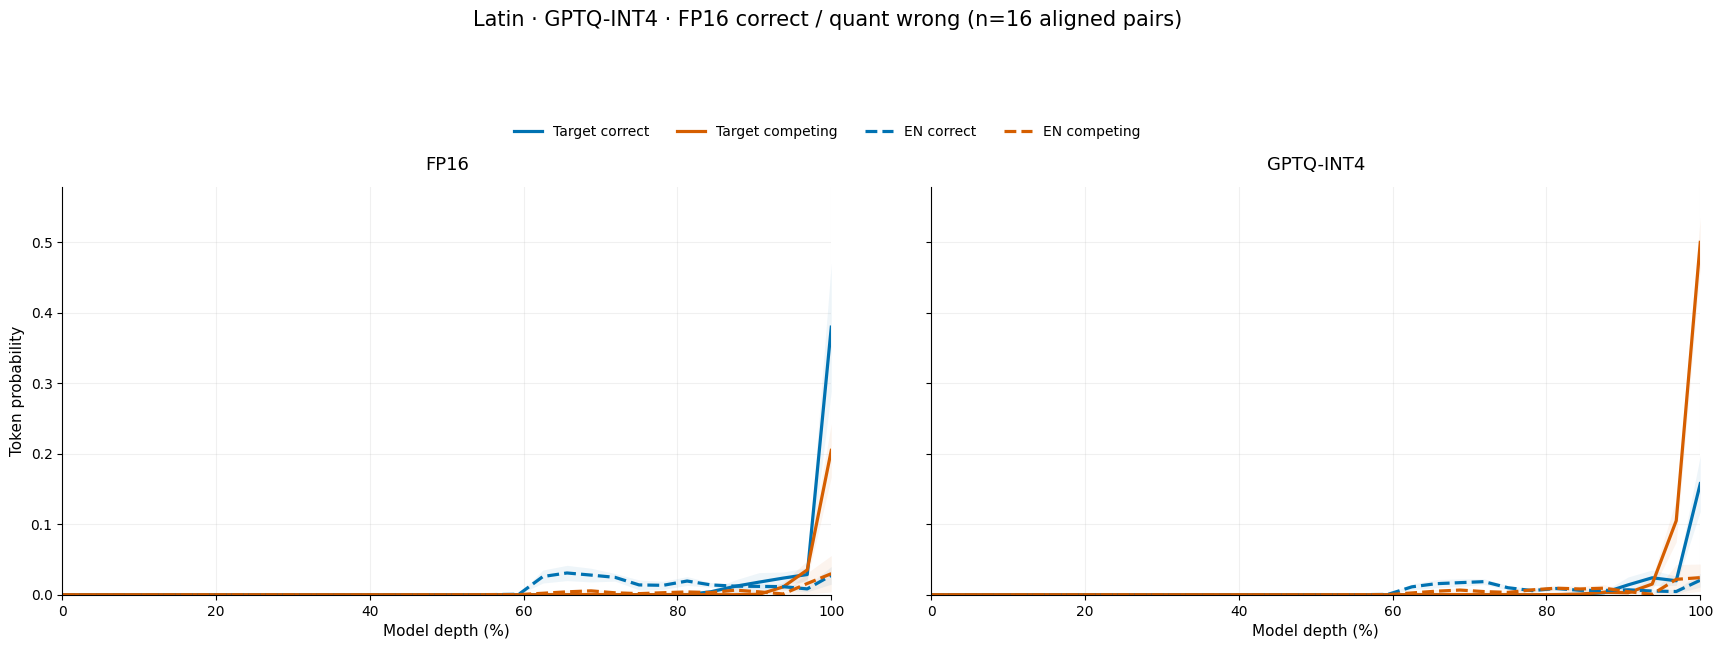

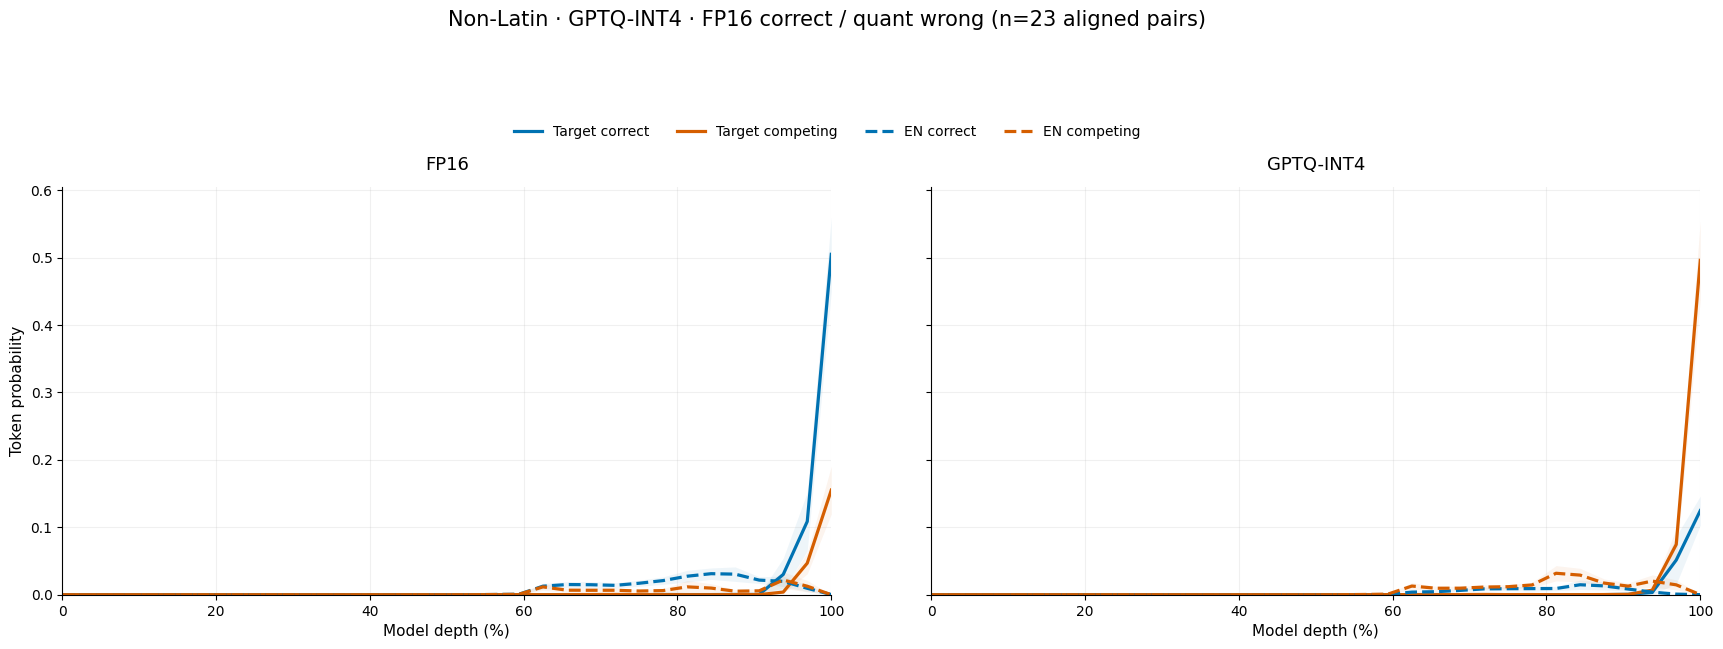

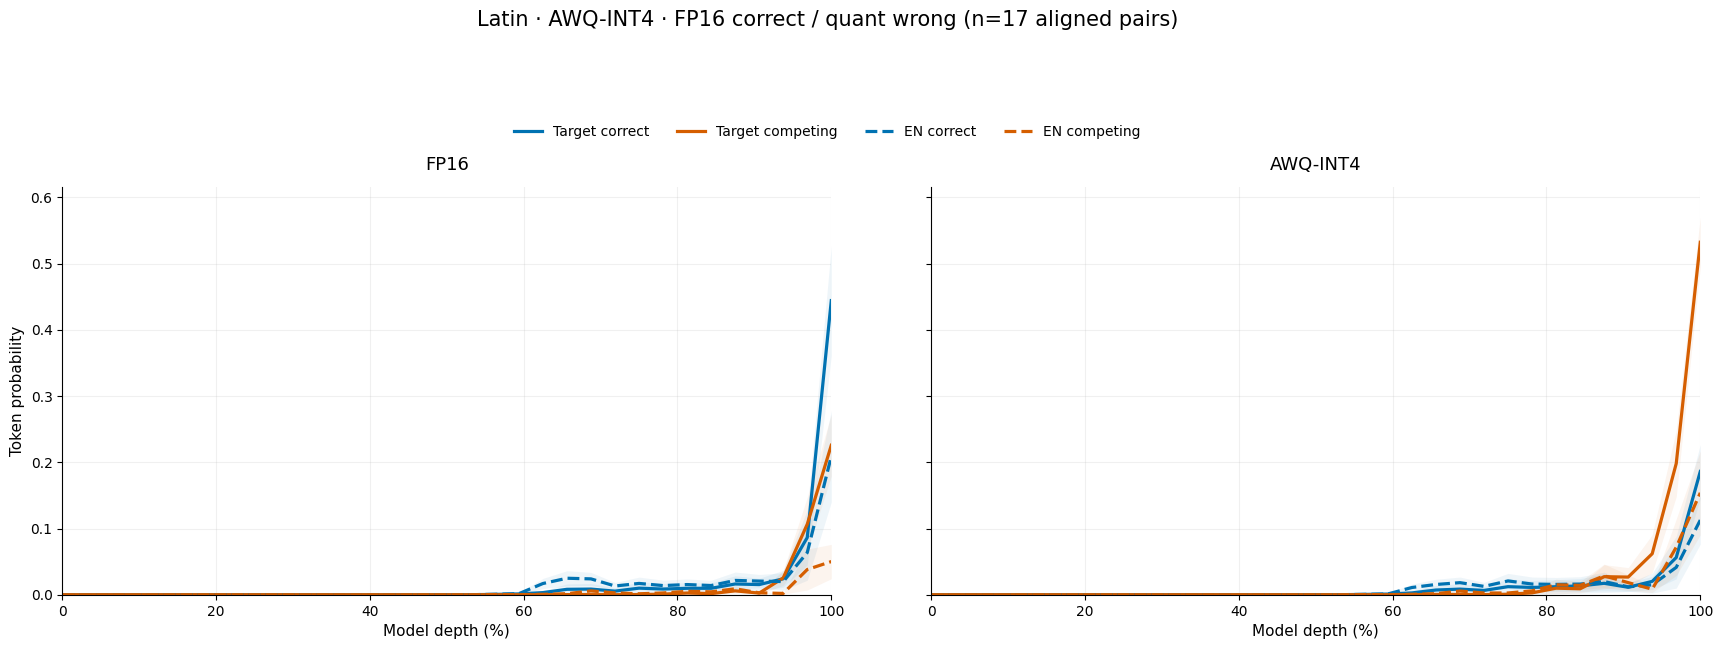

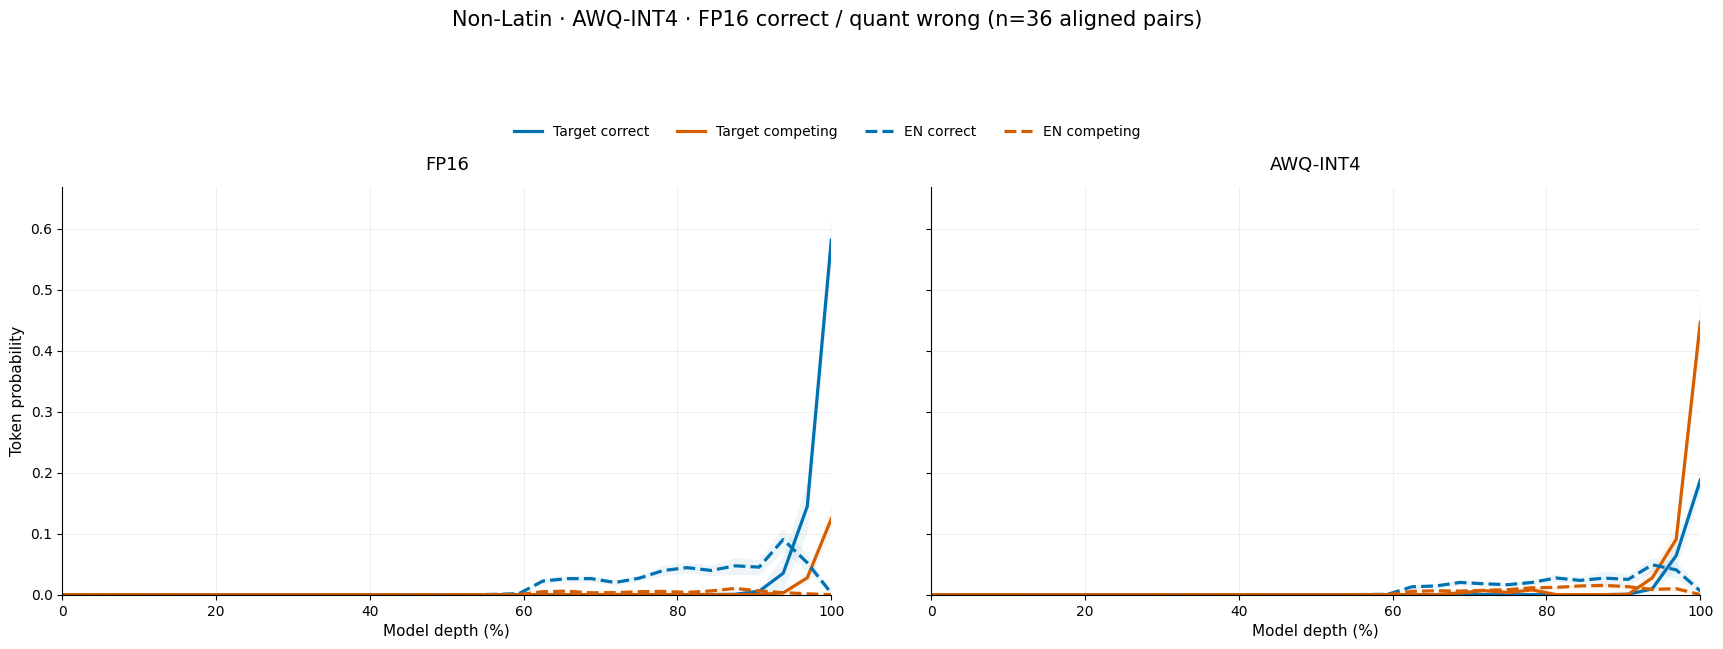

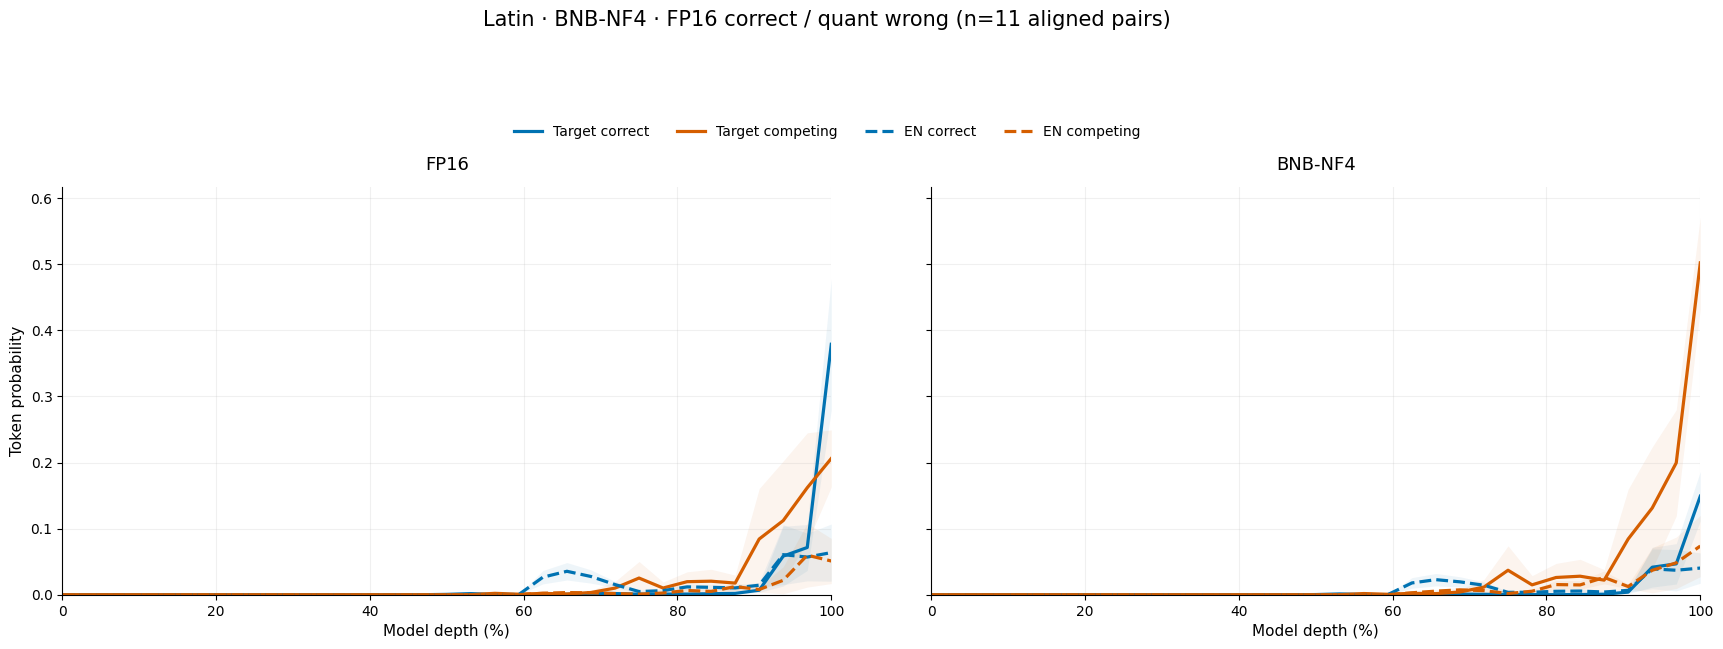

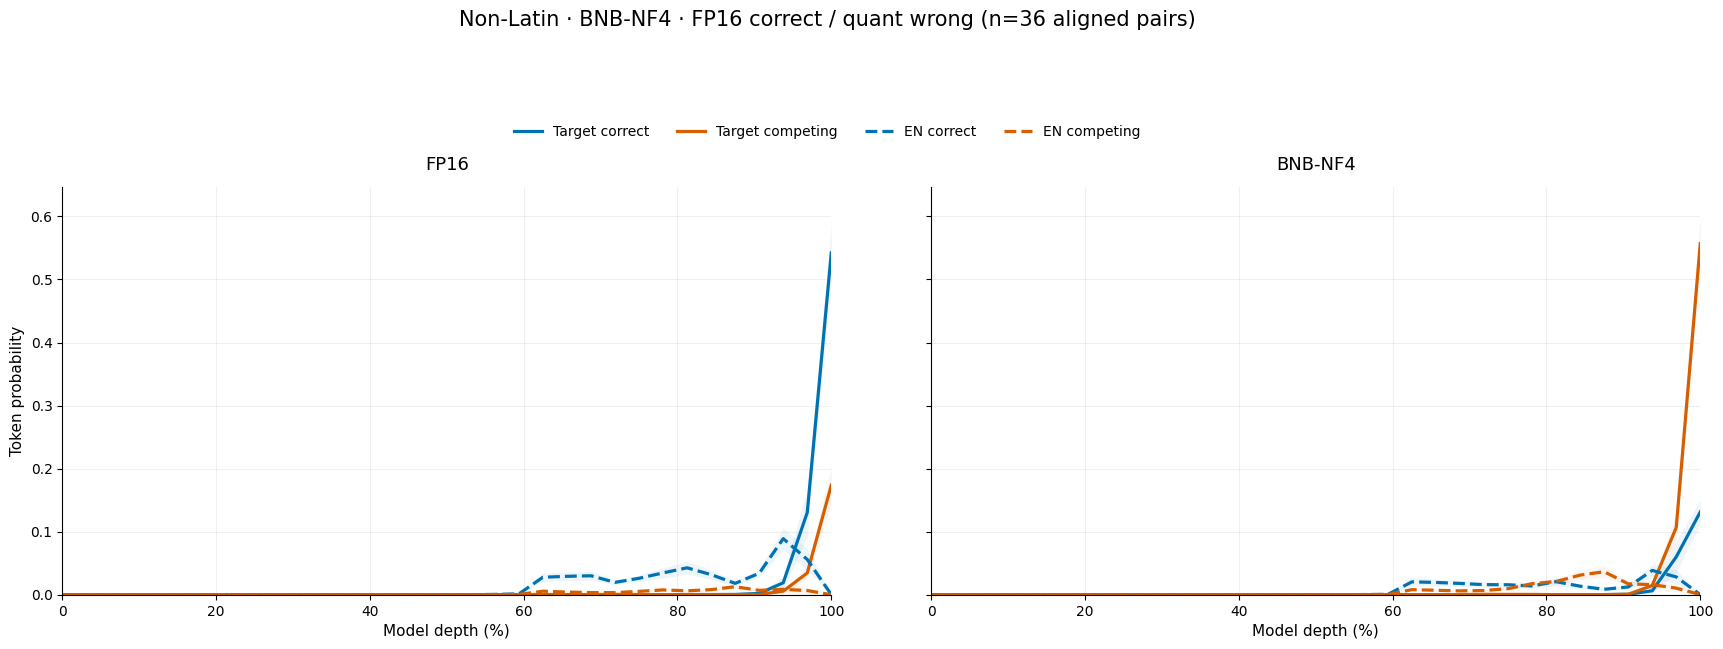

In [10]:
if not RUN_LOGIT_LENS:
    print('RUN_LOGIT_LENS=False: skipped lens aggregation and figures.')
else:
    lens_rows = []
    for method in READY_METHODS:
        probes = LENS_BY_METHOD[method]
        if not probes:
            continue
        expected = {probe['probe_id'] for probe in probes}
        for model_label, source_model in [('FP16', 'FP16'), ('quant', method)]:
            cache, _ = read_cache(lens_cache_path(model_label, method),
                                  SIGNATURES[method], expected,
                                  {'probe_id', 'correct_probs_json',
                                   'wrong_probs_json', 'n_hidden_states', 'signature'})
            if set(cache) != expected:
                raise RuntimeError(f'Incomplete lens cache: {method}/{source_model}')
            for probe in probes:
                record = cache[probe['probe_id']]
                gold = json.loads(record['correct_probs_json'])
                wrong = json.loads(record['wrong_probs_json'])
                n_states = int(record['n_hidden_states'])
                if len(gold) != n_states or len(wrong) != n_states:
                    raise RuntimeError(f"Malformed lens vectors: {probe['probe_id']}")
                for layer_index in range(n_states):
                    common = {'method': method, 'source_model': source_model,
                              'sample_id': probe['sample_id'],
                              'language': probe['language'],
                              'script_group': probe['script_group'],
                              'outcome': probe['outcome'],
                              'answer_language': probe['answer_language'],
                              'layer_index': layer_index,
                              'depth_pct': 100 * layer_index / (n_states - 1)}
                    lens_rows.append({**common, 'candidate_type': 'correct',
                                      'token_probability': gold[layer_index]})
                    if wrong[layer_index] is not None:
                        lens_rows.append({**common, 'candidate_type': 'wrong',
                                          'token_probability': wrong[layer_index]})

    lens_df = pd.DataFrame(lens_rows)
    lens_df.to_csv(FOUR_GROUP_DIR / 'bilingual_lens_sample_layer_probabilities.csv',
                   index=False, encoding='utf-8-sig')
    language_lens_summary = (lens_df.groupby(
        ['method', 'outcome', 'script_group', 'language', 'source_model',
         'answer_language', 'candidate_type', 'layer_index', 'depth_pct'], as_index=False)
        .agg(n_samples=('sample_id', 'nunique'),
             mean_probability=('token_probability', 'mean'),
             std_probability=('token_probability', 'std')))
    language_lens_summary.to_csv(
        FOUR_GROUP_DIR / 'bilingual_lens_by_language_mean_std.csv',
        index=False, encoding='utf-8-sig')
    display(language_lens_summary.head(12))

    script_lens_summary = (lens_df.groupby(
        ['method', 'script_group', 'source_model', 'answer_language',
         'candidate_type', 'layer_index', 'depth_pct'], as_index=False)
        .agg(n_samples=('sample_id', 'nunique'),
             mean_probability=('token_probability', 'mean'),
             std_probability=('token_probability', 'std')))
    script_lens_summary['se_probability'] = (
        script_lens_summary.std_probability.fillna(0) /
        np.sqrt(script_lens_summary.n_samples.clip(lower=1))
    )
    script_lens_summary.to_csv(
        FOUR_GROUP_DIR / 'bilingual_lens_by_script_group_mean_se.csv',
        index=False, encoding='utf-8-sig')
    display(script_lens_summary.head(12))

    for method in READY_METHODS:
        for script_group in ('Latin', 'Non-Latin'):
            group_data = script_lens_summary[
                script_lens_summary.method.eq(method) &
                script_lens_summary.script_group.eq(script_group)
            ]
            if group_data.empty:
                continue
            n_pairs = lens_df[
                lens_df.method.eq(method) &
                lens_df.script_group.eq(script_group)
            ].sample_id.nunique()
            fig, axes = plt.subplots(1, 2, figsize=(18, 6.8), sharex=True,
                                     sharey=True)
            fig.subplots_adjust(left=0.075, right=0.985, bottom=0.13,
                                top=0.73, wspace=0.13)
            all_lowers, all_uppers = [], []
            for ax, source_model in zip(axes, ('FP16', method)):
                panel = group_data[group_data.source_model.eq(source_model)]
                for answer_language, line_style, language_label in (
                    ('target', '-', 'Target'),
                    ('en', '--', 'EN'),
                ):
                    for candidate_type, color, candidate_label in (
                        ('correct', '#0072B2', 'correct'),
                        ('wrong', '#D55E00', 'competing'),
                    ):
                        curve = panel[
                            panel.answer_language.eq(answer_language) &
                            panel.candidate_type.eq(candidate_type)
                        ].sort_values('layer_index')
                        if curve.empty:
                            continue
                        x = curve.depth_pct.to_numpy(float)
                        y = curve.mean_probability.to_numpy(float)
                        se = curve.se_probability.to_numpy(float)
                        lower = np.clip(y - se, 0, 1)
                        upper = np.clip(y + se, 0, 1)
                        all_lowers.append(float(lower.min()))
                        all_uppers.append(float(upper.max()))
                        ax.plot(x, y, color=color, linestyle=line_style,
                                linewidth=2.3, label=f'{language_label} {candidate_label}')
                        ax.fill_between(x, lower, upper, color=color,
                                        alpha=0.065, linewidth=0)
                ax.set_title(source_model, fontsize=13, pad=12)
                ax.set_xlabel('Model depth (%)', fontsize=11)
                ax.set_xlim(0, 100)
                ax.grid(alpha=0.18)
                ax.spines[['top', 'right']].set_visible(False)
            if all_uppers:
                span = max(all_uppers) - min(all_lowers)
                pad = max(0.02 * max(all_uppers), 0.08 * span, 0.001)
                axes[0].set_ylim(max(0, min(all_lowers) - pad),
                                 min(1, max(all_uppers) + pad))
            axes[0].set_ylabel('Token probability', fontsize=11)
            handles, labels = axes[0].get_legend_handles_labels()
            fig.legend(handles, labels, loc='upper center', ncol=4,
                       bbox_to_anchor=(0.5, 0.84), frameon=False, fontsize=10)
            fig.suptitle(
                f'{script_group} · {method} · FP16 correct / quant wrong '
                f'(n={n_pairs} aligned pairs)', y=0.99, fontsize=15
            )
            stem = FOUR_GROUP_DIR / (
                f'{method.lower().replace("-", "_")}_'
                f'{script_group.lower().replace("-", "_")}_bilingual_lens'
            )
            fig.savefig(stem.with_suffix('.png'), dpi=220, bbox_inches='tight')
            fig.savefig(stem.with_suffix('.pdf'), bbox_inches='tight')
            plt.show()
